In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- 0. STYLE CONFIGURATION ---
def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 20, "axes.labelsize" : 20,
        "legend.fontsize" : 14, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 18,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 18,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [6]:
# --- 1. DATA EXTRACTION ---
pkl_file = "fiducial_452Halos_FullSpectra_new.pkl"
H_HUBBLE = 0.6774

print(f"--> Loading {pkl_file}...")
df_all = pd.read_pickle(pkl_file)

# Find the innermost radius
inner_radius = df_all['r_multiplier'].min()
df_inner = df_all[df_all['r_multiplier'] == inner_radius].copy()

# Extract Mass and Equivalent Width (EW)
massas_log10 = np.log10((df_inner['halo_mass'] * 1e10) / H_HUBBLE)
ew_values = df_inner['eq_width']
halo_ids = df_inner['halo_id']
r200 = df_inner['halo_r200_mpc']

# Clean DataFrame
df_scatter = pd.DataFrame({
    'halo_id': halo_ids,
    'log_mass_msun': massas_log10,
    'eq_width': ew_values,
    'r200_2': r200**2
})

print(f"--> Data extracted for innermost radius: b = {inner_radius:.2f} R_200")
print(f"--> Total skewers (scatter points): {len(df_scatter)}")

--> Loading fiducial_452Halos_FullSpectra_new.pkl...
--> Data extracted for innermost radius: b = 0.10 R_200
--> Total skewers (scatter points): 5424


In [7]:
# --- 2. BINNED STATISTICS (The "Stacking" equivalent for EW) ---
# Create 8 mass bins across the mass range
num_bins = 20
mass_bins = np.linspace(df_scatter['log_mass_msun'].min(), df_scatter['log_mass_msun'].max(), num_bins + 1)
bin_centers = 0.5 * (mass_bins[:-1] + mass_bins[1:])

# Calculate mean and standard deviation of EW in each mass bin
df_scatter['mass_bin'] = pd.cut(df_scatter['log_mass_msun'], bins=mass_bins)
binned_stats = df_scatter.groupby('mass_bin', observed=False)['eq_width'].agg(['mean', 'std']).reset_index()
binned_stats_r200 = df_scatter.groupby('mass_bin', observed=False)['r200_2'].agg(['mean', 'std']).reset_index()



--> Plot saved as: Scatter_EW_vs_Mass_InnerRadius.pdf


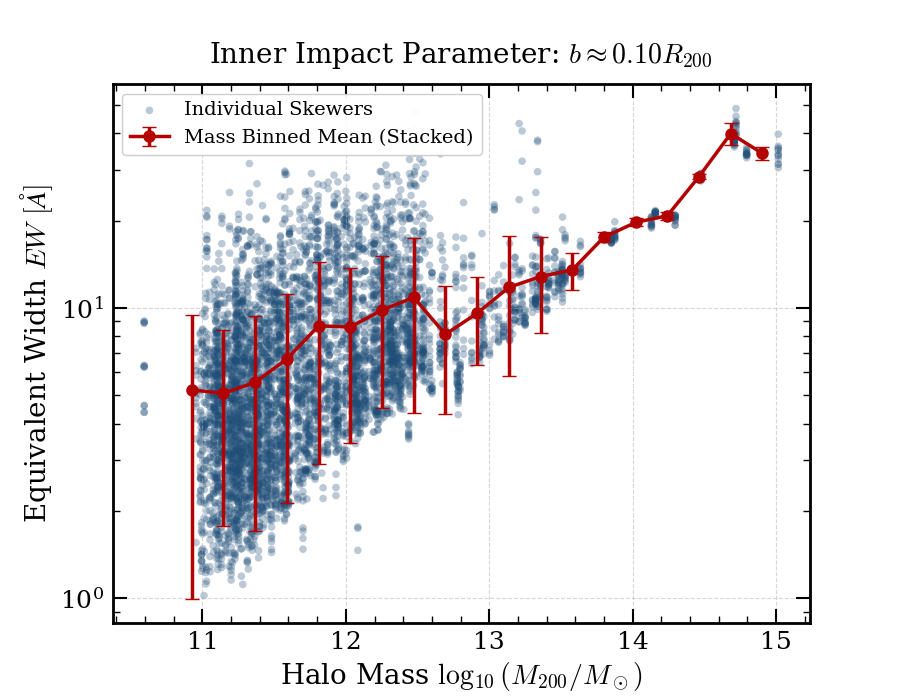

In [8]:
# --- 3. PLOTTING ---
fig, ax = plt.subplots(figsize=(9, 7))

# Plot 1: The Scatter (Cloud of individual skewers)
ax.scatter(df_scatter['log_mass_msun'], df_scatter['eq_width'], 
           color='#1f4e78', alpha=0.3, edgecolor='none', s=30, zorder=1, label='Individual Skewers')

# Plot 2: The Stacked Trend (Binned mean + std deviation)
ax.errorbar(bin_centers, binned_stats['mean'], yerr=binned_stats['std'],
            fmt='o-', color='#b30000', linewidth=2.5, capsize=5, markersize=8, 
            zorder=5, label='Mass Binned Mean (Stacked)')


# Formatting
ax.set_xlabel(r'Halo Mass $\log_{10}(M_{200} / M_\odot)$')
ax.set_ylabel(r'Equivalent Width $EW\ [\AA]$')
ax.set_title(f"Inner Impact Parameter: $b \\approx {inner_radius:.2f} R_{{200}}$", pad=15)

# Add grid and legend
ax.grid(True, linestyle='--', alpha=0.5, zorder=0)
ax.legend(loc='upper left', framealpha=0.95)

# Adjust y-limits to start from 0 for EW
#ax.set_ylim(bottom=0)
ax.set_yscale('log')

# Save and show
output_file = "Scatter_EW_vs_Mass_InnerRadius.pdf"
plt.savefig(output_file, bbox_inches='tight', dpi=300)
print(f"\n--> Plot saved as: {output_file}")

plt.show()


--> Plot saved as: Scatter_EW_vs_Mass_InnerRadius.pdf


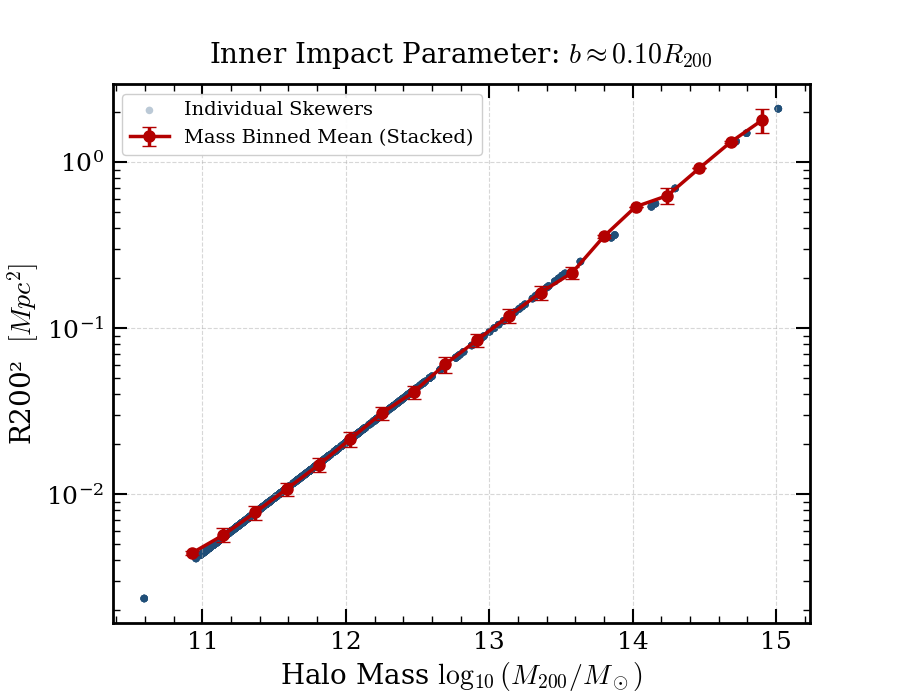

In [10]:
# --- 3. PLOTTING ---
fig, ax = plt.subplots(figsize=(9, 7))

# Plot 1: The Scatter (Cloud of individual skewers)
ax.scatter(df_scatter['log_mass_msun'], df_scatter['r200_2'], 
           color='#1f4e78', alpha=0.3, edgecolor='none', s=30, zorder=1, label='Individual Skewers')

# Plot 2: The Stacked Trend (Binned mean + std deviation)
ax.errorbar(bin_centers, binned_stats_r200['mean'], yerr=binned_stats_r200['std'],
            fmt='o-', color='#b30000', linewidth=2.5, capsize=5, markersize=8, 
            zorder=5, label='Mass Binned Mean (Stacked)')


# Formatting
ax.set_xlabel(r'Halo Mass $\log_{10}(M_{200} / M_\odot)$')
ax.set_ylabel(r'R200² $\ [Mpc^2]$')
ax.set_title(f"Inner Impact Parameter: $b \\approx {inner_radius:.2f} R_{{200}}$", pad=15)

# Add grid and legend
ax.grid(True, linestyle='--', alpha=0.5, zorder=0)
ax.legend(loc='upper left', framealpha=0.95)

# Adjust y-limits to start from 0 for EW
#ax.set_ylim(bottom=0)
ax.set_yscale('log')

# Save and show
output_file = "Scatter_EW_vs_Mass_InnerRadius.pdf"
plt.savefig(output_file, bbox_inches='tight', dpi=300)
print(f"\n--> Plot saved as: {output_file}")

plt.show()

## Comparing re-sims

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- 0. STYLE CONFIGURATION ---
def matplotlib_default_config():
    font = {'family' : 'serif', 'weight' : 'normal', 'size' : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 20, "axes.labelsize" : 20,
        "legend.fontsize" : 14, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 18,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 18,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

# Apply Config
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- 1. PARAMETERS & FILES ---
PKL_FIDUCIAL = "Fiducial_452Halos_FullSpectra.pkl" # Change to _Fixed.pkl if needed
PKL_LH0 = "LH_0_452Halos_FullSpectra.pkl"
PKL_LH1 = "LH_1_452Halos_FullSpectra.pkl"
H_HUBBLE = 0.6774

# Colors for differentiation
COLOR_FID = '#1f4e78' # Strong Blue
COLOR_LH0 = '#b30000' # Strong Red
COLOR_LH1 = "#06b300" # Strong greeb


# --- 2. DATA LOADING & PREP ---
if not os.path.exists(PKL_FIDUCIAL) or not os.path.exists(PKL_LH0):
    print("ERROR: One of the .pkl files was not found.")
    import sys; sys.exit()

df_fid_all = pd.read_pickle(PKL_FIDUCIAL)
df_lh0_all = pd.read_pickle(PKL_LH0)
df_lh1_all = pd.read_pickle(PKL_LH1)


# Identify the innermost radius (assumes both have the same inner radius)
inner_radius = df_fid_all['r_multiplier'].min()

# Filter DataFrames to only include the innermost radius
df_fid = df_fid_all[df_fid_all['r_multiplier'] == inner_radius].copy()
df_lh0 = df_lh0_all[df_lh0_all['r_multiplier'] == inner_radius].copy()
df_lh1 = df_lh1_all[df_lh1_all['r_multiplier'] == inner_radius].copy()


# Calculate log10 Halo Mass
df_fid['log_mass_msun'] = np.log10((df_fid['halo_mass'] * 1e10) / H_HUBBLE)
df_lh0['log_mass_msun'] = np.log10((df_lh0['halo_mass'] * 1e10) / H_HUBBLE)
df_lh1['log_mass_msun'] = np.log10((df_lh1['halo_mass'] * 1e10) / H_HUBBLE)


# Extract Equivalent Width (EW)
# We filter out any EW <= 0 to avoid issues with log scale plotting later
df_fid = df_fid[df_fid['eq_width'] > 0]
df_lh0 = df_lh0[df_lh0['eq_width'] > 0]
df_lh1 = df_lh1[df_lh1['eq_width'] > 0]


# --- 3. BINNED STATISTICS (Mass Stacking) ---
num_bins = 20

# Determine global mass limits so bins are identical for both models
global_min_mass = min(df_fid['log_mass_msun'].min(), df_lh0['log_mass_msun'].min(), df_lh1['log_mass_msun'].min())
global_max_mass = max(df_fid['log_mass_msun'].max(), df_lh0['log_mass_msun'].max(), df_lh1['log_mass_msun'].max())

# Create common mass bins
mass_bins = np.linspace(global_min_mass, global_max_mass, num_bins + 1)
bin_centers = 0.5 * (mass_bins[:-1] + mass_bins[1:])

# Group and calculate mean & std for Fiducial
df_fid['mass_bin'] = pd.cut(df_fid['log_mass_msun'], bins=mass_bins)
stats_fid = df_fid.groupby('mass_bin', observed=False)['eq_width'].agg(['mean', 'std']).reset_index()

# Group and calculate mean & std for LH_0
df_lh0['mass_bin'] = pd.cut(df_lh0['log_mass_msun'], bins=mass_bins)
stats_lh0 = df_lh0.groupby('mass_bin', observed=False)['eq_width'].agg(['mean', 'std']).reset_index()

# Group and calculate mean & std for LH_1
df_lh1['mass_bin'] = pd.cut(df_lh1['log_mass_msun'], bins=mass_bins)
stats_lh1 = df_lh1.groupby('mass_bin', observed=False)['eq_width'].agg(['mean', 'std']).reset_index()

In [10]:
df_lh1['eq_width'].shape, df_lh1['log_mass_msun'].shape

((5409,), (5409,))


--> Plot saved as: Scatter_EW_vs_Mass_Comparison.pdf


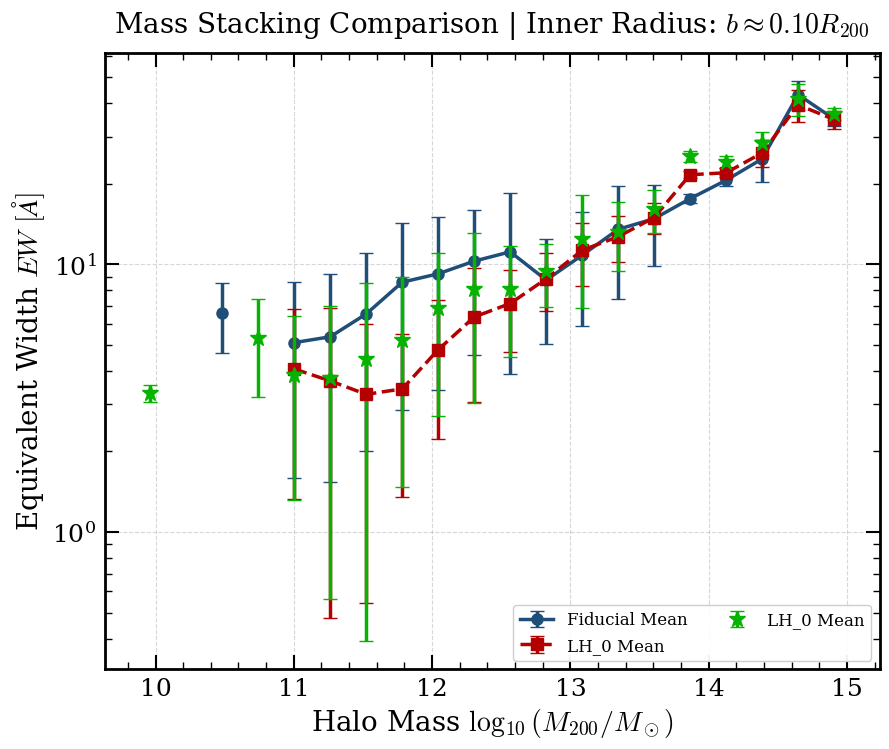

In [17]:
# --- 4. PLOTTING ---
fig, ax = plt.subplots(figsize=(10, 8))
"""
# A. Plot the Scatter Clouds (Individual Skewers)
# Using low alpha so they don't overpower the stacked trends
ax.scatter(df_fid['log_mass_msun'], df_fid['eq_width'], 
           color=COLOR_FID, alpha=0.15, edgecolor='none', s=30, zorder=1, label='Fiducial (Scatter)')

ax.scatter(df_lh0['log_mass_msun'], df_lh0['eq_width'], 
           color=COLOR_LH0, alpha=0.15, edgecolor='none', s=30, zorder=2, label='LH_0 (Scatter)')

ax.scatter(df_lh1['log_mass_msun'], df_lh1['eq_width'], 
           color=COLOR_LH1, alpha=0.15, edgecolor='none', s=30, zorder=2, label='LH_1 (Scatter)')
"""

# B. Plot the Stacked Trends (Binned Means)
# Fiducial: Solid line, circular markers
ax.errorbar(bin_centers, stats_fid['mean'], yerr=stats_fid['std'],
            fmt='o-', color=COLOR_FID, linewidth=2.5, capsize=5, markersize=8, 
            zorder=10, label='Fiducial Mean')

# LH_0: Dashed line, square markers to distinguish easily
ax.errorbar(bin_centers, stats_lh0['mean'], yerr=stats_lh0['std'],
            fmt='s--', color=COLOR_LH0, linewidth=2.5, capsize=5, markersize=8, 
            zorder=11, label='LH_0 Mean')

ax.errorbar(bin_centers, stats_lh1['mean'], yerr=stats_lh1['std'],
            fmt='*', color=COLOR_LH1, linewidth=2.5, capsize=5, markersize=12, 
            zorder=11, label='LH_0 Mean')

# C. Formatting
ax.set_xlabel(r'Halo Mass $\log_{10}(M_{200} / M_\odot)$')
ax.set_ylabel(r'Equivalent Width $EW\ [\AA]$')
ax.set_title(f"Mass Stacking Comparison | Inner Radius: $b \\approx {inner_radius:.2f} R_{{200}}$", pad=15)

# Set Y-axis to Log Scale (as done in the user's previous plot)
ax.set_yscale('log')

# Add grid and format legend
ax.grid(True, linestyle='--', alpha=0.5, zorder=0)
ax.legend(loc='lower right', framealpha=0.95, fontsize=12, ncol=2)

# Adjust limits if necessary to make it look clean
ax.set_xlim(global_min_mass - 0.2, global_max_mass + 0.2)

# Save and show
output_file = "Scatter_EW_vs_Mass_Comparison.pdf"
plt.savefig(output_file, bbox_inches='tight', dpi=300)
print(f"\n--> Plot saved as: {output_file}")

plt.show()

--> Loading /home/vroberto/FakeSpectra_DLAs/notebooks/LH_0_452Halos_FullSpectra.pkl...

--> Plot saved as: Scatter_EW_vs_Mass_AllRadii.pdf


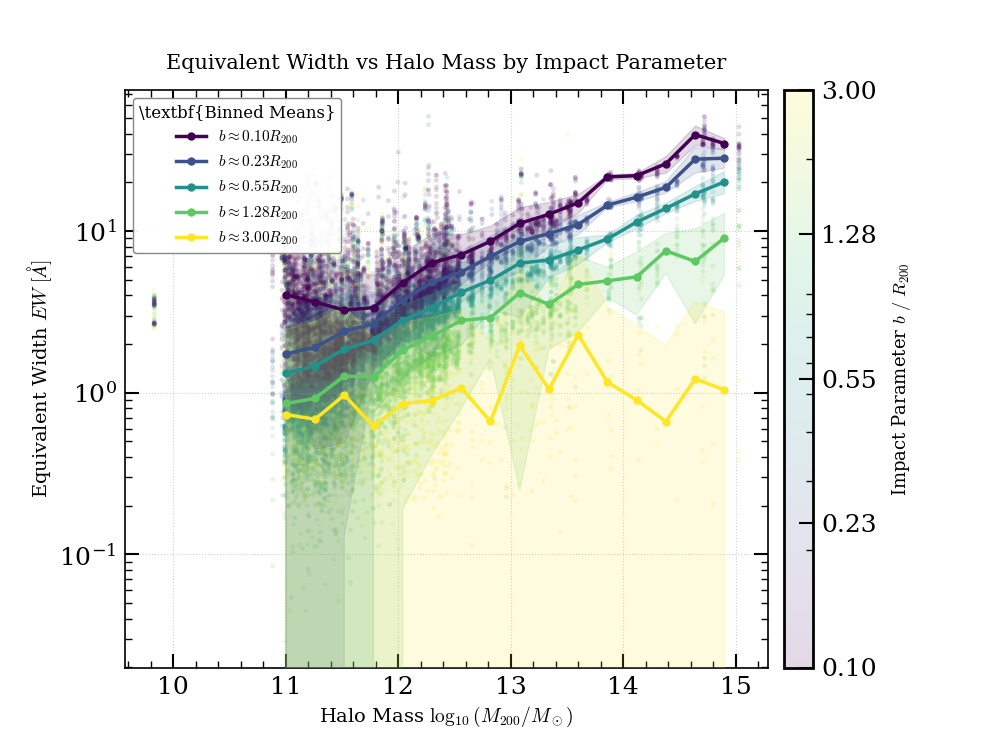

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
%matplotlib widget 


# --- 1. DATA EXTRACTION ---
pkl_file = "/home/vroberto/FakeSpectra_DLAs/notebooks/LH_0_452Halos_FullSpectra.pkl"
H_HUBBLE = 0.6774

print(f"--> Loading {pkl_file}...")
# Assumindo que seu DataFrame já contém todos os dados
df_all = pd.read_pickle(pkl_file)

# Calcular a massa em log10 para todos os dados
df_all['log_mass_msun'] = np.log10((df_all['halo_mass'] * 1e10) / H_HUBBLE)

# Obter os raios únicos e ordená-los (do maior para o menor)
# Plotar os raios maiores primeiro garante que os pontos mais próximos (menor r) 
# fiquem por cima, já que costumam ter EW maior e mais interessante.
unique_radii = np.sort(df_all['r_multiplier'].unique())
df_all = df_all.sort_values(by='r_multiplier', ascending=False)

# --- 2. SETUP DA FIGURA E COLORMAP ---
fig, ax = plt.subplots(figsize=(10, 7.5))

# Criar um colormap profissional (viridis, plasma, magma, etc.)
cmap = plt.get_cmap('viridis')

# Usar escala logarítmica para mapear a cor devido ao espaçamento dos raios
norm = mcolors.LogNorm(vmin=unique_radii.min(), vmax=unique_radii.max())

# --- 3. PLOT SCATTER (A Nuvem de Fundo) ---
sc = ax.scatter(
    df_all['log_mass_msun'], 
    df_all['eq_width'],
    c=df_all['r_multiplier'], 
    cmap=cmap, 
    norm=norm,
    alpha=0.15,          # Transparência alta para não poluir
    s=12,                # Tamanho pequeno
    edgecolors='none', 
    zorder=1
)

# Adicionar a Colorbar para o Scatter
cbar = plt.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label(r'Impact Parameter $b \ / \ R_{200}$', fontsize=13, labelpad=10)
# Ajustar os "ticks" do colorbar para mostrar exatamente seus valores de raio
cbar.set_ticks(unique_radii)
cbar.set_ticklabels([f"{r:.2f}" for r in unique_radii])

# --- 4. BINNED STATISTICS (Tendências Sobrepostas) ---
num_bins = 20
mass_bins = np.linspace(df_all['log_mass_msun'].min(), df_all['log_mass_msun'].max(), num_bins + 1)
bin_centers = 0.5 * (mass_bins[:-1] + mass_bins[1:])

# Fazer um loop pelos raios (agora do menor para o maior para a legenda ficar ordenada)
for r_val in sorted(unique_radii):
    df_r = df_all[df_all['r_multiplier'] == r_val].copy()
    
    # Calcular as estatísticas binned
    df_r['mass_bin'] = pd.cut(df_r['log_mass_msun'], bins=mass_bins)
    binned_stats = df_r.groupby('mass_bin', observed=False)['eq_width'].agg(['mean', 'std']).reset_index()
    
    # Obter a exata cor correspondente a este raio no colormap
    color = cmap(norm(r_val))
    
    # Plotar a Linha de Média (sólida e bem visível)
    ax.plot(
        bin_centers, binned_stats['mean'], 
        marker='o', color=color, linewidth=2.5, markersize=5, 
        zorder=5, label=f'$b \\approx {r_val:.2f} R_{{200}}$'
    )
    
    # Plotar o Desvio Padrão como Região Sombreada (mais limpo que barras de erro)
    # Se quiser mostrar o erro da média, troque 'std' por 'std' / sqrt(N)
    ax.fill_between(
        bin_centers, 
        binned_stats['mean'] - binned_stats['std'], 
        binned_stats['mean'] + binned_stats['std'], 
        color=color, alpha=0.15, zorder=4
    )

# --- 5. FORMATTING (Deixando com cara de artigo) ---
ax.set_xlabel(r'Halo Mass $\log_{10}(M_{200} / M_\odot)$', fontsize=14)
ax.set_ylabel(r'Equivalent Width $EW\ [\AA]$', fontsize=14)
ax.set_title("Equivalent Width vs Halo Mass by Impact Parameter", fontsize=15, pad=15)

ax.set_yscale('log')

# Customização da Legenda das linhas
ax.legend(
    loc='upper left', 
    title=r'\textbf{Binned Means}', 
    framealpha=0.95, 
    fontsize=11, 
    title_fontsize=12,
    edgecolor='gray'
)

# Grid discreto por trás
ax.grid(True, linestyle=':', alpha=0.6, zorder=0)

# Ajustar espessura dos eixos para parecer mais profissional
for spine in ax.spines.values():
    spine.set_linewidth(1.2)

# Save and show
output_file = "Scatter_EW_vs_Mass_AllRadii.pdf"
plt.savefig(output_file, bbox_inches='tight', dpi=300)
print(f"\n--> Plot saved as: {output_file}")

plt.show()